In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

insurance = pd.read_csv("insurance.csv")
sales = pd.read_csv("sales.csv")

In [20]:
print("Insurance Columns:", insurance.columns.tolist())
print("Sales Columns:", sales.columns.tolist())

Insurance Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
Sales Columns: ['Customer ID', 'Age', 'Gender', 'Loyalty Member', 'Product Type', 'SKU', 'Rating', 'Order Status', 'Payment Method', 'Total Price', 'Unit Price', 'Quantity', 'Purchase Date', 'Shipping Type', 'Add-ons Purchased', 'Add-on Total']


In [24]:
sales.columns = (
    sales.columns
         .str.strip()
         .str.lower()
         .str.replace(" ", "_")
         .str.replace("-", "_")
)

In [26]:
insurance['bmi'] = insurance['bmi'].fillna(insurance['bmi'].median())

In [28]:
sales['customer_id'] = sales['customer_id'].fillna("unknown")
sales['total_price'] = sales['total_price'].fillna(sales['total_price'].median())
sales['unit_price'] = sales['unit_price'].fillna(sales['unit_price'].median())

In [32]:
sales['purchase_date'] = pd.to_datetime(sales['purchase_date'], errors='coerce')

In [34]:
insurance = insurance.drop_duplicates()
sales = sales.drop_duplicates()

In [36]:
insurance['smoker_flag'] = insurance['smoker'].map({'yes': 1, 'no': 0})

In [38]:
sales['loyalty_flag'] = sales['loyalty_member'].map({
    'Yes': 1, 'Y': 1, 'No': 0, 'N': 0
})

In [40]:
insurance['age_group'] = pd.cut(
    insurance['age'],
    bins=[0,20,30,40,50,60,70],
    labels=['0-20','21-30','31-40','41-50','51-60','61-70']
)

In [42]:
sales['age_group'] = pd.cut(
    sales['age'],
    bins=[0,20,30,40,50,60,70],
    labels=['0-20','21-30','31-40','41-50','51-60','61-70']
)

In [44]:
loyalty_spending = sales.pivot_table(
    index='product_type',
    values='total_price',
    columns='loyalty_flag',
    aggfunc='mean'
)

In [46]:
insurance['merge_key'] = 1
sales['merge_key'] = 1

merged_data = insurance.merge(sales, on='merge_key').drop('merge_key', axis=1)

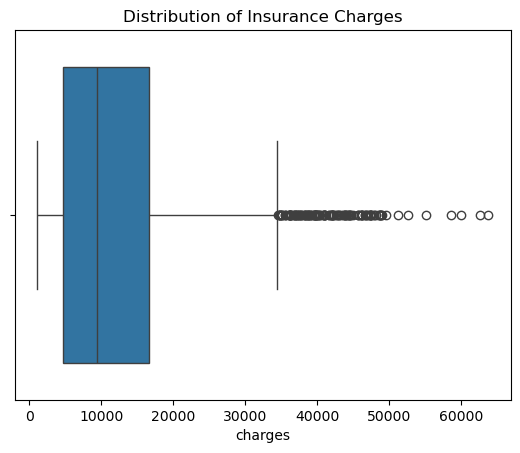

In [47]:
sns.boxplot(x=insurance['charges'])
plt.title("Distribution of Insurance Charges")
plt.show()

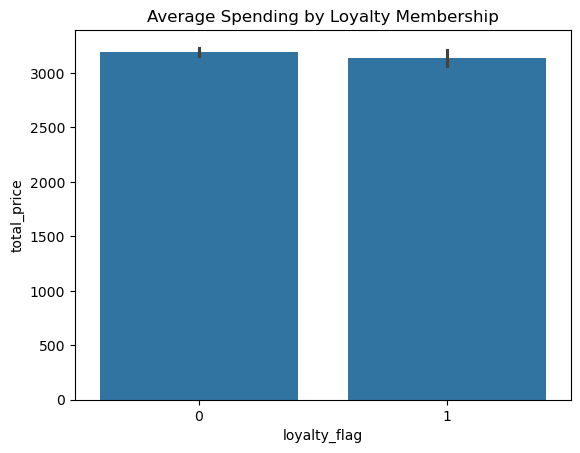

In [50]:
sns.barplot(data=sales, x='loyalty_flag', y='total_price')
plt.title("Average Spending by Loyalty Membership")
plt.show()

In [80]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression

In [82]:
# Load insurance dataset
insurance = pd.read_csv("insurance.csv")

# Encode smoker
insurance['smoker_flag'] = insurance['smoker'].map({'yes': 1, 'no': 0})

# Fix missing BMI
insurance['bmi'] = insurance['bmi'].fillna(insurance['bmi'].median())

# Define features & target
X_ins = insurance[['age', 'bmi', 'children', 'smoker_flag', 'region']]
y_ins = insurance['charges']

# One-hot encode "region"
ct = ColumnTransformer(
    transformers=[
        ('region_encoder', OneHotEncoder(), ['region'])
    ],
    remainder='passthrough'
)

# Train/test split
X_train_ins, X_test_ins, y_train_ins, y_test_ins = train_test_split(
    X_ins, y_ins, test_size=0.2, random_state=42
)

# Build regression pipeline
reg_model = Pipeline(steps=[
    ('encoder', ct),
    ('model', LinearRegression())
])

# Train model
reg_model.fit(X_train_ins, y_train_ins)

# Predict
y_pred_ins = reg_model.predict(X_test_ins)

# Metrics
mse = mean_squared_error(y_test_ins, y_pred_ins)
rmse = np.sqrt(mse)

print("\n==== Insurance Regression Model ====")
print("RMSE:", rmse)



==== Insurance Regression Model ====
RMSE: 5796.766728796435


In [84]:
# Load sales dataset
sales = pd.read_csv("sales.csv")

# Standardize column names
sales.columns = (
    sales.columns
         .str.strip()
         .str.lower()
         .str.replace(" ", "_")
         .str.replace("-", "_")
)

# Create loyalty_flag
sales['loyalty_flag'] = sales['loyalty_member'].map({
    'Yes': 1, 'Y': 1, 'No': 0, 'N': 0
})

# Drop rows where target or features are missing BEFORE splitting
sales = sales.dropna(subset=[
    'loyalty_flag',
    'age',
    'total_price',
    'unit_price',
    'quantity',
    'add_on_total'
])

# Features for ML
X_sales = sales[['age', 'total_price', 'unit_price', 'quantity', 'add_on_total']]
y_sales = sales['loyalty_flag']

# Train/test split
X_train_sales, X_test_sales, y_train_sales, y_test_sales = train_test_split(
    X_sales, y_sales, test_size=0.2, random_state=42
)

# Classification model
clf = LogisticRegression(max_iter=500)
clf.fit(X_train_sales, y_train_sales)

# Predictions
y_pred_sales = clf.predict(X_test_sales)

# Sanity check: lengths must match
print("len(y_test) =", len(y_test_sales))
print("len(y_pred) =", len(y_pred_sales))

# Metrics
acc = accuracy_score(y_test_sales, y_pred_sales)
f1 = f1_score(y_test_sales, y_pred_sales)

print("\n==== Loyalty Classification Model ====")
print("Accuracy:", acc)
print("F1 Score:", f1)


len(y_test) = 4000
len(y_pred) = 4000

==== Loyalty Classification Model ====
Accuracy: 0.779
F1 Score: 0.0


In [86]:
def recommend_customer(row):
    recs = []
    
    # Spending-based suggestions
    if row['total_price'] > 500:
        recs.append("Recommend loyalty membership for cashback rewards.")
    else:
        recs.append("Recommend discount coupons to increase engagement.")
    
    # Add-on recommendation
    if row['add_on_total'] > 50:
        recs.append("Suggest premium add-ons or accessory bundles.")
        
    # Age-based suggestions
    if row['age'] >= 50:
        recs.append("Recommend preventive health check-up reminders.")
    else:
        recs.append("Recommend fitness and lifestyle products.")
    
    return recs

# Apply recommendations
sales['recommendations'] = sales.apply(recommend_customer, axis=1)

sales[['customer_id', 'total_price', 'add_on_total', 'age', 'recommendations']].head()


,customer_id,total_price,add_on_total,age,recommendations
0,1000,5538.33,40.21,53,[Recommend loyalty membership for cashback rew...
1,1000,741.09,26.09,53,[Recommend loyalty membership for cashback rew...
2,1002,1855.84,0.00,41,[Recommend loyalty membership for cashback rew...
3,1002,3164.76,60.16,41,[Recommend loyalty membership for cashback rew...
4,1003,41.50,35.56,75,[Recommend discount coupons to increase engage...


In [88]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

# Select features
cb_features = sales[['age', 'total_price', 'quantity', 'unit_price']]

# Scale
scaler = MinMaxScaler()
cb_scaled = scaler.fit_transform(cb_features)

# Compute similarity matrix
similarity = cosine_similarity(cb_scaled)

def recommend_similar_customers(index, top_n=3):
    sim_scores = list(enumerate(similarity[index]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    top_customers = sim_scores[1:top_n+1]   # skip self
    return [i for i, score in top_customers]

# Example: Recommend for customer at row 10
recommended_indices = recommend_similar_customers(10)

sales.iloc[recommended_indices][['customer_id', 'product_type', 'total_price']]


,customer_id,product_type,total_price
7113,7424,Tablet,2470.3
8387,8538,Tablet,2470.3
9867,9892,Tablet,2470.3


In [90]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

cluster_features = sales[['age', 'total_price', 'unit_price', 'add_on_total']]
cluster_df = cluster_features.dropna()

kmeans = KMeans(n_clusters=3, random_state=42)
sales['cluster'] = kmeans.fit_predict(cluster_df)

sales[['customer_id', 'cluster', 'total_price', 'add_on_total']].head()


,customer_id,cluster,total_price,add_on_total
0,1000,1,5538.33,40.21
1,1000,0,741.09,26.09
2,1002,0,1855.84,0.00
3,1002,1,3164.76,60.16
4,1003,0,41.50,35.56


In [92]:
sales.head()

,customer_id,age,gender,loyalty_member,product_type,sku,rating,order_status,payment_method,total_price,unit_price,quantity,purchase_date,shipping_type,add_ons_purchased,add_on_total,loyalty_flag,recommendations,cluster
0,1000,53,Male,No,Smartphone,SKU1004,2,Cancelled,Credit Card,5538.33,791.19,7,2024-03-20,Standard,"Accessory,Accessory,Accessory",40.21,0,[Recommend loyalty membership for cashback rew...,1
1,1000,53,Male,No,Tablet,SKU1002,3,Completed,Paypal,741.09,247.03,3,2024-04-20,Overnight,Impulse Item,26.09,0,[Recommend loyalty membership for cashback rew...,0
2,1002,41,Male,No,Laptop,SKU1005,3,Completed,Credit Card,1855.84,463.96,4,2023-10-17,Express,NaN,0.00,0,[Recommend loyalty membership for cashback rew...,0
3,1002,41,Male,Yes,Smartphone,SKU1004,2,Completed,Cash,3164.76,791.19,4,2024-08-09,Overnight,"Impulse Item,Impulse Item",60.16,1,[Recommend loyalty membership for cashback rew...,1
4,1003,75,Male,Yes,Smartphone,SKU1001,5,Completed,Cash,41.50,20.75,2,2024-05-21,Express,Accessory,35.56,1,[Recommend discount coupons to increase engage...,0


In [94]:
insurance.head()

,age,sex,bmi,children,smoker,region,charges,smoker_flag
0,19,female,27.900,0,yes,southwest,16884.92400,1
1,18,male,33.770,1,no,southeast,1725.55230,0
2,28,male,33.000,3,no,southeast,4449.46200,0
3,33,male,22.705,0,no,northwest,21984.47061,0
4,32,male,28.880,0,no,northwest,3866.85520,0


In [98]:
import pandas as pd
insurance = pd.read_csv("insurance.csv")
insurance['smoker_flag'] = insurance['smoker'].map({'yes': 1, 'no': 0})
ins_corr = insurance[['age', 'bmi', 'children', 'smoker_flag', 'charges']].corr()
print("Insurance dataset correlation matrix:")
print(ins_corr)

Insurance dataset correlation matrix:
                  age       bmi  children  smoker_flag   charges
age          1.000000  0.109272  0.042469    -0.025019  0.299008
bmi          0.109272  1.000000  0.012759     0.003750  0.198341
children     0.042469  0.012759  1.000000     0.007673  0.067998
smoker_flag -0.025019  0.003750  0.007673     1.000000  0.787251
charges      0.299008  0.198341  0.067998     0.787251  1.000000


In [100]:
sales = pd.read_csv("sales.csv")
sales.columns = (
    sales.columns
         .str.strip()
         .str.lower()
         .str.replace(" ", "_")
         .str.replace("-", "_")
)
sales['loyalty_flag'] = sales['loyalty_member'].map({'Yes': 1, 'Y': 1, 'No': 0, 'N': 0})
sales_corr = sales[['age', 'total_price', 'unit_price', 'quantity', 'add_on_total', 'rating', 'loyalty_flag']].corr()
print("Sales dataset correlation matrix:")
print(sales_corr)

Sales dataset correlation matrix:
                   age  total_price  unit_price  quantity  add_on_total  \
age           1.000000     0.003096   -0.004402  0.008555     -0.005291   
total_price   0.003096     1.000000    0.673951  0.653872      0.083924   
unit_price   -0.004402     0.673951    1.000000  0.006715      0.125189   
quantity      0.008555     0.653872    0.006715  1.000000      0.003419   
add_on_total -0.005291     0.083924    0.125189  0.003419      1.000000   
rating        0.002949    -0.232429   -0.343829 -0.008587     -0.044338   
loyalty_flag  0.000045    -0.008835   -0.005417 -0.005354      0.000577   

                rating  loyalty_flag  
age           0.002949      0.000045  
total_price  -0.232429     -0.008835  
unit_price   -0.343829     -0.005417  
quantity     -0.008587     -0.005354  
add_on_total -0.044338      0.000577  
rating        1.000000      0.004754  
loyalty_flag  0.004754      1.000000  


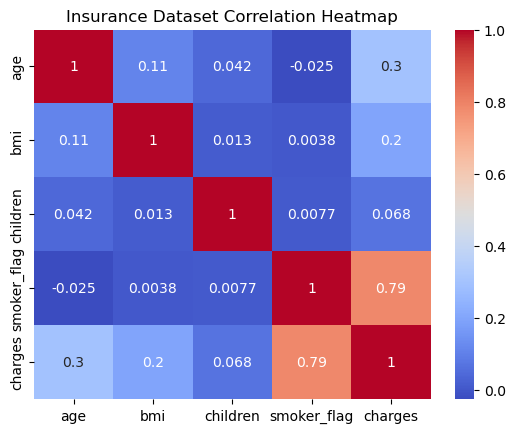

In [105]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(ins_corr, annot=True, cmap="coolwarm")
plt.title("Insurance Dataset Correlation Heatmap")
plt.show()


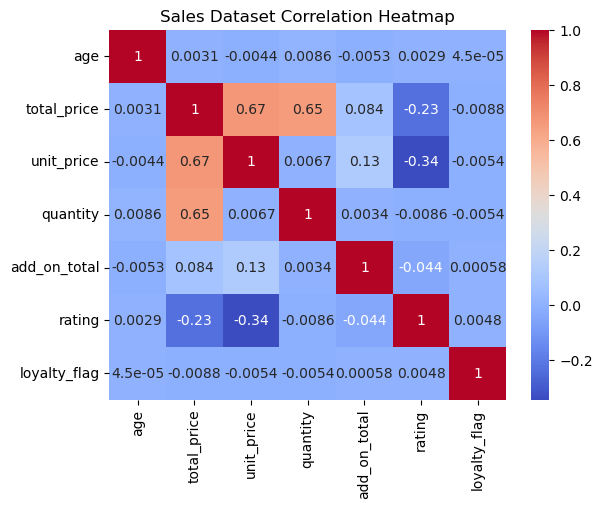

In [107]:
sns.heatmap(sales_corr, annot=True, cmap="coolwarm")
plt.title("Sales Dataset Correlation Heatmap")
plt.show()

In [109]:
import pandas as pd

# 1. Load and clean sales data (if not already done)
sales = pd.read_csv("sales.csv")

sales.columns = (
    sales.columns
         .str.strip()
         .str.lower()
         .str.replace(" ", "_")
         .str.replace("-", "_")
)

# optional: create loyalty_flag if needed elsewhere
sales['loyalty_flag'] = sales['loyalty_member'].map({'Yes':1, 'Y':1, 'No':0, 'N':0})

# 2. Define thresholds for segments (you can tune these)
AFFLUENT_SPEND = 500        # high total spend
HIGH_ADDON_SPEND = 50       # high add-on purchases
OLDER_AGE = 50              # "older" consumers
YOUNG_AGE = 35              # "younger" consumers


# 3. Rule-based recommendation function
def recommend_row(row):
    recs = []

    # Affluent consumers
    if row['total_price'] >= AFFLUENT_SPEND:
        recs.append("Offer loyalty cashback or high-tier points incentive.")

    # Older consumers
    if row['age'] >= OLDER_AGE:
        recs.append("Recommend preventive check-up reminders and health benefits.")

    # High add-on purchasers
    if row['add_on_total'] >= HIGH_ADDON_SPEND:
        recs.append("Recommend bundled or accessory products.")

    # Younger consumers
    if row['age'] <= YOUNG_AGE:
        recs.append("Suggest lifestyle, fitness, and wellness activities.")

    # If nothing matched, give a generic engagement rec
    if not recs:
        recs.append("Send general loyalty promotion to encourage engagement.")

    # join list as single string for easier export
    return " | ".join(recs)

# 4. Apply recommender to each customer/transaction
sales['recommendation'] = sales.apply(recommend_row, axis=1)

# 5. See a few examples
sales[['customer_id', 'age', 'total_price', 'add_on_total', 'recommendation']].head()


,customer_id,age,total_price,add_on_total,recommendation
0,1000,53,5538.33,40.21,Offer loyalty cashback or high-tier points inc...
1,1000,53,741.09,26.09,Offer loyalty cashback or high-tier points inc...
2,1002,41,1855.84,0.00,Offer loyalty cashback or high-tier points inc...
3,1002,41,3164.76,60.16,Offer loyalty cashback or high-tier points inc...
4,1003,75,41.50,35.56,Recommend preventive check-up reminders and he...
